<center><h1>bagai_sanchit_HW3</h1></center>
<br>
<br>

Name: Sanchit Bagai
<br>
Github Username: baked-potatoes
<br>
USC ID: 1033382623

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import f_classif

Get the AReM Data Set

In [2]:
data_dir = "../data/AReM"

files = sorted(glob.glob(os.path.join(data_dir, "**", "dataset*.csv"), recursive=True))
print("number of files:", len(files))

cols = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def read_instance(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = [p for p in re.split(r"[,\s]+", line) if p]
            try:
                vals = [float(p) for p in parts]
            except ValueError:
                continue
            if len(vals) == 7:
                rows.append(vals[1:])
    return pd.DataFrame(rows, columns=cols)

instances = []
for p in files:
    activity = os.path.basename(os.path.dirname(p))
    num = int(re.search(r"dataset(\d+)", os.path.basename(p)).group(1))
    df = read_instance(p)
    instances.append({"activity": activity, "num": num, "data": df})

print(pd.Series([len(i["data"]) for i in instances]).value_counts())  

number of files: 88
480    87
479     1
Name: count, dtype: int64


### (b) Test and Train Data

In [3]:
def is_test(inst):
    if inst["activity"] in ("bending1", "bending2"):
        return inst["num"] in (1, 2)
    return inst["num"] in (1, 2, 3)

train = [i for i in instances if not is_test(i)]
test  = [i for i in instances if is_test(i)]
print("train:", len(train), " test:", len(test))
print(pd.Series([i["activity"] for i in train]).value_counts().to_dict())

train: 69  test: 19
{'cycling': 12, 'lying': 12, 'sitting': 12, 'standing': 12, 'walking': 12, 'bending1': 5, 'bending2': 4}


### (c) Feature Extraction

#### i. Research

Time-domain features are computed directly from the raw values of a time series, with no transformation to the frequency domain. Features commonly used in time series classification include:

- **Location / central tendency:** minimum, maximum, mean, median, mode, first quartile (Q1), third quartile (Q3), other percentiles
- **Spread / dispersion:** standard deviation, variance, range (max - min), interquartile range (Q3 - Q1), mean absolute deviation
- **Shape of the distribution:** skewness, kurtosis
- **Energy / magnitude:** root mean square (RMS), signal energy (sum of squares), sum of absolute values
- **Dynamics / temporal structure:** zero-crossing rate or mean-crossing rate, number of peaks, slope of a linear trend, mean absolute change between consecutive values, autocorrelation at selected lags, time at which the max / min occurs
- **Other:** first and last value, sample entropy

#### ii. Extraction

In [4]:
def extract(inst):
    feats = {}
    for k, c in enumerate(cols, start=1):
        x = inst["data"][c].values
        feats[f"min{k}"]       = x.min()
        feats[f"max{k}"]       = x.max()
        feats[f"mean{k}"]      = x.mean()
        feats[f"median{k}"]    = np.median(x)
        feats[f"std{k}"]       = x.std(ddof=1)
        feats[f"1st_quart{k}"] = np.percentile(x, 25)
        feats[f"3rd_quart{k}"] = np.percentile(x, 75)
    return feats

features_all = pd.DataFrame([extract(i) for i in instances])
features_all.insert(0, "Instance", range(1, len(instances) + 1))

activity = pd.Series([i["activity"] for i in instances], name="activity")
test_mask = np.array([is_test(i) for i in instances])

features_train = features_all[~test_mask].reset_index(drop=True)
features_test  = features_all[test_mask].reset_index(drop=True)
y_train = activity[~test_mask].reset_index(drop=True)
y_test  = activity[test_mask].reset_index(drop=True)

print(features_all.shape, features_train.shape, features_test.shape)
features_all.head()

(88, 43) (69, 43) (19, 43)


,Instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


#### iii. Standard Deviation

In [5]:
feature_cols = [c for c in features_all.columns if c not in ("Instance", "activity", "split")]
X = features_all[feature_cols].values
n = X.shape[0]

rng = np.random.default_rng(552)
B = 2000
boot_std = np.empty((B, X.shape[1]))
for b in range(B):
    idx = rng.integers(0, n, n)
    boot_std[b] = X[idx].std(axis=0, ddof=1)

ci = pd.DataFrame({
    "std": X.std(axis=0, ddof=1),
    "CI_5%": np.percentile(boot_std, 5, axis=0),
    "CI_95%": np.percentile(boot_std, 95, axis=0),
}, index=feature_cols)
pd.set_option("display.max_rows", 100)
ci.round(4)

,std,CI_5%,CI_95%
min1,9.5700,8.2745,10.8133
max1,4.3944,3.3983,5.2858
mean1,5.3357,4.6877,5.8933
median1,5.4401,4.8013,5.9993
std1,1.7722,1.5683,1.9485
1st_quart1,6.1536,5.5956,6.6359
3rd_quart1,5.1389,4.3442,5.8400
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6184,5.4011
mean2,1.5742,1.3942,1.7057


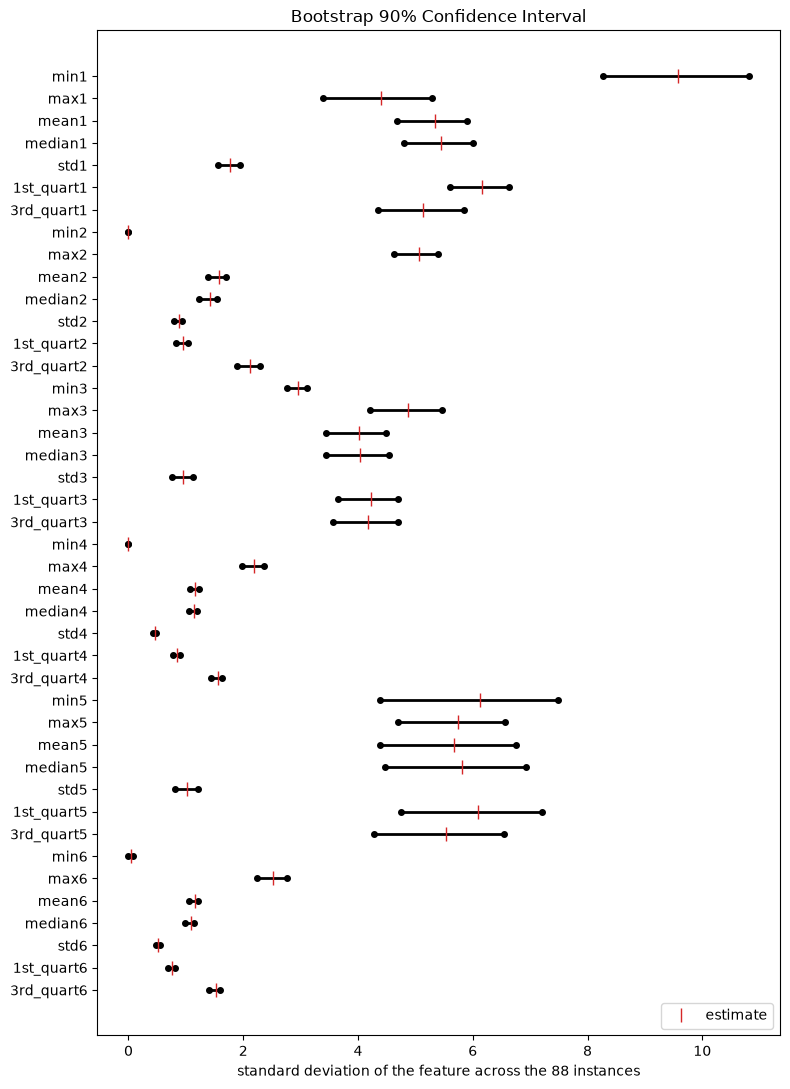

In [6]:
fig, ax = plt.subplots(figsize=(8, 11))
y = np.arange(len(ci))[::-1]                      # first feature at the top
ax.hlines(y, ci["CI_5%"], ci["CI_95%"], color="black", linewidth=2)
ax.plot(ci["CI_5%"],  y, "o", color="black", markersize=4)
ax.plot(ci["CI_95%"], y, "o", color="black", markersize=4)
ax.plot(ci["std"],    y, "|", color="tab:red", markersize=10, label="estimate")
ax.set_yticks(y)
ax.set_yticklabels(ci.index)
ax.set_xlabel("standard deviation of the feature across the 88 instances")
ax.set_title("Bootstrap 90% Confidence Interval")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### iv. Select Features

In [7]:
import warnings
stats = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]

train_std = features_train[feature_cols].std()
print("constant features:", train_std[train_std == 0].index.tolist())

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    F, p = f_classif(features_train[feature_cols], y_train)
F = pd.Series(F, index=feature_cols).fillna(0)

F_grid = pd.DataFrame({k: [F[f"{s}{k}"] for s in stats] for k in range(1, 7)},
                      index=stats)
F_grid.columns = [f"series {k}" for k in range(1, 7)]
F_grid["mean F"] = F_grid.mean(axis=1)
print("\nANOVA F-score by feature type (rows) and time series (columns):")
display(F_grid.round(1).sort_values("mean F", ascending=False))

corr = sum(features_train[[f"{s}{k}" for s in stats]].corr().abs().fillna(0).values
           for k in range(1, 7)) / 6
corr = pd.DataFrame(corr, index=stats, columns=stats)
print("\naverage |correlation| between feature types (high = redundant):")
display(corr.round(2))

constant features: ['min2', 'min4']

ANOVA F-score by feature type (rows) and time series (columns):


,series 1,series 2,series 3,series 4,series 5,series 6,mean F
mean,15.9,900.2,26.4,651.8,33.4,581.5,368.2
3rd_quart,8.5,807.0,28.1,561.9,32.2,664.8,350.4
median,17.5,477.0,19.4,800.8,28.6,563.1,317.7
1st_quart,21.4,265.5,21.2,244.8,25.5,346.3,154.1
std,9.1,360.9,15.2,128.6,7.8,133.4,109.2
max,1.5,47.7,31.7,29.3,37.0,33.0,30.0
min,11.0,0.0,22.7,0.0,24.1,0.8,9.8



average |correlation| between feature types (high = redundant):


,min,max,mean,median,std,1st_quart,3rd_quart
min,0.67,0.24,0.39,0.38,0.26,0.40,0.35
max,0.24,1.00,0.79,0.75,0.63,0.71,0.82
mean,0.39,0.79,1.00,0.99,0.60,0.98,0.98
median,0.38,0.75,0.99,1.00,0.61,0.98,0.96
std,0.26,0.63,0.60,0.61,1.00,0.66,0.57
1st_quart,0.40,0.71,0.98,0.98,0.66,1.00,0.93
3rd_quart,0.35,0.82,0.98,0.96,0.57,0.93,1.00


I selected **mean, standard deviation and maximum**.

- **Mean:** It has the highest average ANOVA F-score of all feature types (368) and is especially strong for the variance series (e.g. F = 900 for series 2). The median, 1st quartile and 3rd quartile carry almost the same information (average absolute correlation with the mean of 0.98 to 0.99), so I keep only one of them.
- **Standard deviation:** It measures spread rather than level, so it adds different information (average absolute correlation with the mean of 0.60).
- **Maximum:** It captures the extremes of the signal and is less correlated with the mean (0.79) than the median and quartiles. It also has the highest F-score for series 3 and 5, where the mean is weaker.

I did not use the minimum: `min2` and `min4` are constant, so their F-statistics are undefined (shown as 0 in the table only because missing values were filled with 0), and `min6` is almost constant.

The correlations are averages over the six series and the F-scores come from the training set for all 7 activities, so they guide the choice rather than prove it.

## 2. ISLR 3.7.4

### (a) Linear Train

The **cubic regression** would have the lower training RSS. The cubic model contains the linear model as a special case (set β2 = β3 = 0), so least squares can always fit the training data at least as well with the extra terms. This holds even though the true relationship is linear, because the cubic terms will pick up some of the random noise.

### (b) Linear Test

The **linear regression** would have the lower test RSS. The true relationship is linear, so the linear model has little bias and low variance. The cubic model has extra flexibility that fit the noise in the training data (overfitting), and that noise does not carry over to new observations, so its test RSS is higher.

### (c) Not Linear Train

The **cubic regression** would again have the lower training RSS. This does not depend on the true form of the relationship: a more flexible model that contains the simpler one can never have a higher training RSS.

### (d) Not Linear Testing

There is **not enough information to tell**. It depends on how far the true relationship is from linear. If it is strongly non-linear (closer to cubic), the linear model has high bias and the cubic regression would have the lower test RSS. If it is only slightly non-linear, the extra variance of the cubic fit could outweigh the reduction in bias, and the linear regression could still have the lower test RSS.

## 3. ISLR 3.7.3 - Extra Practice 

Model: Salary = 50 + 20 GPA + 0.07 IQ + 35 Level + 0.01 GPA·IQ − 10 GPA·Level, where Level = 1 for college and 0 for high school (salary in thousands of dollars).

**(a)** For a fixed IQ and GPA, college minus high school is 35 − 10·GPA. This is positive only when GPA < 3.5, so for a high enough GPA (above 3.5) high school graduates earn more on average. **Answer iii is correct.**

**(b)** IQ = 110, GPA = 4.0, college (Level = 1):

50 + 20(4.0) + 0.07(110) + 35(1) + 0.01(4.0)(110) − 10(4.0)(1) = **137.1**, about \$137,100.

**(c)** **False.** The size of a coefficient does not show whether there is evidence of an interaction. It depends on the units of the predictors: GPA·IQ is around 400 here, so a coefficient of 0.01 is a noticeable effect. To judge the evidence we need the standard error of the coefficient and its p-value (the t-test for H0: β4 = 0).

## 3. ISLR 3.7.5 - Extra Practice 

For regression through the origin (no intercept), the least squares estimate is

$$\hat\beta = \frac{\sum_{i=1}^{n} x_i y_i}{\sum_{j=1}^{n} x_j^2}$$

so the fitted value for observation $i$ is

$$\hat y_i = x_i \hat\beta = \sum_{i'=1}^{n} \frac{x_i x_{i'}}{\sum_{j=1}^{n} x_j^2}\, y_{i'}$$

Therefore

$$a_{i'} = \frac{x_i\, x_{i'}}{\sum_{j=1}^{n} x_j^2}$$

Each fitted value $\hat y_i$ is a linear combination of all the responses $y_1, \dots, y_n$.

### AI Use log:

**Prompt:**
I've attached my Homework 3 assignment PDF and my notebook template for context. Can you help me work through Problem 1 and the ISLR questions? For each part, explain the steps and include the relevant Python code with suggested variable names, plus the written answers, so I can run and test everything myself on the AReM data.

(Uploaded Homework3.pdf and bagai_sanchit_HW3.ipynb for context)

**Response:**
### 1(a) and 1(b) Load the Data and Split into Train and Test

Read every `dataset*.csv` file, skipping the `#` comment lines and keeping rows with 7 numeric fields (`time` plus the 6 series). Store each file as an instance with its activity (the folder name) and its dataset number.

```python
files = sorted(glob.glob(os.path.join(data_dir, "**", "dataset*.csv"), recursive=True))

def is_test(inst):
    if inst["activity"] in ("bending1", "bending2"):
        return inst["num"] in (1, 2)
    return inst["num"] in (1, 2, 3)

train = [i for i in instances if not is_test(i)]
test  = [i for i in instances if is_test(i)]
```

This gives 88 instances, 69 for training and 19 for testing.

### 1(c)i Research

Common time-domain features for time series classification include location measures (min, max, mean, median, quartiles), spread (standard deviation, variance, range, IQR), shape (skewness, kurtosis), energy (RMS, sum of squares), dynamics (zero-crossing rate, number of peaks, trend, autocorrelation) and entropy measures such as sample entropy.

### 1(c)ii Extraction

For each of the 6 series, compute the min, max, mean, median, standard deviation, first quartile and third quartile, giving 42 features per instance.

```python
def extract(inst):
    feats = {}
    for k, c in enumerate(cols, start=1):
        x = inst["data"][c].values
        feats[f"min{k}"]       = x.min()
        feats[f"max{k}"]       = x.max()
        feats[f"mean{k}"]      = x.mean()
        feats[f"median{k}"]    = np.median(x)
        feats[f"std{k}"]       = x.std(ddof=1)
        feats[f"1st_quart{k}"] = np.percentile(x, 25)
        feats[f"3rd_quart{k}"] = np.percentile(x, 75)
    return feats

features_all = pd.DataFrame([extract(i) for i in instances])
features_all.insert(0, "Instance", range(1, len(instances) + 1))
```

Keep the labels (`y_train`, `y_test`) separate from the feature table so the table matches the format in the assignment.

### 1(c)iii Standard Deviation and Bootstrap Confidence Intervals

Estimate the standard deviation of each feature across the 88 instances, then resample the instances with replacement (2000 times) and take the 5th and 95th percentiles of the bootstrapped standard deviations as a 90% confidence interval.

```python
rng = np.random.default_rng(552)
boot_std = np.empty((B, X.shape[1]))
for b in range(B):
    idx = rng.integers(0, n, n)
    boot_std[b] = X[idx].std(axis=0, ddof=1)

ci = pd.DataFrame({
    "std": X.std(axis=0, ddof=1),
    "CI_5%": np.percentile(boot_std, 5, axis=0),
    "CI_95%": np.percentile(boot_std, 95, axis=0),
}, index=feature_cols)
```

The same `ci` table can be drawn as an interval plot (`ax.hlines` for the intervals and a marker for the estimate).

### 1(c)iv Select Features

Check for constant features, rank each feature type with an ANOVA F-score on the training set, and look at how strongly the feature types are correlated.

```python
F, p = f_classif(features_train[feature_cols], y_train)
corr = features_train[[f"{s}{k}" for s in stats]].corr().abs()
```

Constant features (here `min2` and `min4`) have undefined F-statistics. The mean, median, 1st quartile and 3rd quartile are highly correlated with one another, so only one of them is needed. Based on the F-scores and the correlations, the mean, standard deviation and maximum are a reasonable set of three features. The correlations are averages over the six series and the F-scores are for all 7 activities, so they guide the choice rather than prove it.

### 2. ISLR 3.7.4

* **(a)** The cubic regression has the lower training RSS, because it contains the linear model as a special case.
* **(b)** The linear regression has the lower test RSS, because the cubic model overfits the noise when the true relationship is linear.
* **(c)** The cubic regression again has the lower training RSS, since a more flexible model always fits the training data at least as well.
* **(d)** There is not enough information to tell. It depends on how far the true relationship is from linear (bias versus variance).

### 3. Extra Practice (ISLR 3.7.3 and 3.7.5)

**3.7.3:**
* **(a)** For fixed IQ and GPA, college minus high school is \(35 - 10 \cdot GPA\), which is positive only when GPA is below 3.5. Answer iii is correct.
* **(b)** The prediction for IQ 110, GPA 4.0 and a college graduate is 137.1 (about 137,100 dollars).
* **(c)** False. The size of a coefficient does not show evidence of an interaction; the standard error and p-value are needed.

**3.7.5:** For regression through the origin, \(\hat\beta = \sum_i x_i y_i / \sum_j x_j^2\), so \(\hat y_i = \sum_{i'} a_{i'} y_{i'}\) with \(a_{i'} = \dfrac{x_i x_{i'}}{\sum_{j} x_j^2}\).

A short numerical check of 3.7.3(b) and 3.7.5 can be done in Python with `np.isclose`.

### References:

* numpy.percentile: [https://numpy.org/doc/stable/reference/generated/numpy.percentile.html](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html)
* numpy Generator.integers (bootstrap resampling): [https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.integers.html](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.integers.html)
* scikit-learn f_classif: [https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html)
* pandas DataFrame.corr: [https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
* matplotlib Axes.hlines: [https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hlines.html](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hlines.html)